## Nội dung thực hành

| Buổi | Nội dung trọng tâm | Kết quả cần nộp |
|---|---|---|
| 1 | Dataset khó, pretrained model, input normalization, thay head | Kiểm tra tensor / số tham số / chia dữ liệu |
| 2 | Từ đầu và **linear probing** với backbone đóng băng | Bảng loss, accuracy, macro-F1, learning curves |
| 3 | **Partial** và **full fine-tuning**, BatchNorm, learning rate theo tầng | So sánh 4 cách học trên validation |
| 4 | Test độc lập, dự đoán sai, checkpoint, thảo luận giới hạn | Bảng tổng kết và bài tập mở rộng |

**Quy tắc khoa học:** không xem test khi chỉnh mô hình; mọi nhận xét mang tính quan sát trên một lần chạy, không phải kết luận thống kê về ưu thế tuyệt đối.

## 0. Thiết lập và kiểm soát tái lập

- **Sử dụng CUDA:** Notebook cố định `DEVICE = torch.device("cuda:0")`.
- **Seed = 42:**
- **Thời lượng:** số epoch đã chạy trong output là `5/25/5/5` cho Scratch/Probe/Partial/Full.
- **Thư viện:** dùng PyTorch/torchvision đã có trong Colab;


In [29]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
IMAGE_SIZE = 224
NUM_CLASSES = 100
EPOCHS_SCRATCH = 5
EPOCHS_PROBE = 25
EPOCHS_PARTIAL = 5
EPOCHS_FULL = 5
PATIENCE = 4
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./bai6_aircraft_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), "Bài 6 yêu cầu GPU CUDA: Runtime → Change runtime type → T4 GPU."
DEVICE = torch.device("cuda:0")
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1


def set_seed(seed: int = SEED) -> None:
    """Đặt seed cho các thư viện."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("Torch:", torch.__version__, "| Torchvision:", __import__("torchvision").__version__)
print("Thiết bị:", DEVICE, "| Seed:", SEED)
print("Thư mục lưu mô hình:", OUTPUT_DIR.resolve())


Torch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130
Thiết bị: cuda:0 | Seed: 42
Thư mục lưu mô hình: /content/bai6_aircraft_outputs


Cell 1: Kết nối Google Drive và giải nén

In [30]:
import glob
import os
import tarfile
from google.colab import drive

drive.mount('/content/drive')

# Tìm tự động file fgvc-aircraft-2013b.tar trên Google Drive của bạn
default_path = '/content/drive/MyDrive/fgvc-aircraft-2013b.tar'
if os.path.exists(default_path):
  tar_path = default_path
else:
  matches = glob.glob(
      '/content/drive/MyDrive/**/fgvc-aircraft-2013b.tar*', recursive=True
  )
  assert len(matches) > 0, (
      'Không tìm thấy file fgvc-aircraft-2013b.tar trong Google Drive! Hãy kiểm'
      ' tra lại tên file.'
  )
  tar_path = matches[0]

print('Đã tìm thấy file:', tar_path)

DATA_ROOT = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)

# Giải nén vào /content/data -> tạo ra thư mục /content/data/fgvc-aircraft-2013b
if not os.path.exists(os.path.join(DATA_ROOT, 'fgvc-aircraft-2013b')):
  print('Đang giải nén dữ liệu máy bay...')
  with tarfile.open(tar_path, 'r:*') as tar:
    tar.extractall(path=DATA_ROOT)
  print('Giải nén hoàn tất!')
else:
  print('Thư mục dữ liệu đã tồn tại, bỏ qua bước giải nén.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã tìm thấy file: /content/drive/MyDrive/fgvc-aircraft-2013b.tar.gz
Thư mục dữ liệu đã tồn tại, bỏ qua bước giải nén.


Cell 2: Nạp dữ liệu FGVCAircraft và tạo DataLoader (Thay cho cell FlowersNUM_CLASSES cũ)

In [31]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Định nghĩa phép biến đổi ảnh chuẩn ImageNet (224x224)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Nạp bộ dữ liệu máy bay FGVC-Aircraft
DATA_ROOT = '/content/data'

train_dataset = datasets.FGVCAircraft(
    root=DATA_ROOT,
    split='train',
    annotation_level='variant',
    transform=train_transform,
    download=False,
)

val_dataset = datasets.FGVCAircraft(
    root=DATA_ROOT,
    split='val',
    annotation_level='variant',
    transform=eval_transform,
    download=False,
)

test_dataset = datasets.FGVCAircraft(
    root=DATA_ROOT,
    split='test',
    annotation_level='variant',
    transform=eval_transform,
    download=False,
)

NUM_CLASSES = len(train_dataset.classes)
class_names = train_dataset.classes

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True
)

images, labels = next(iter(train_loader))
print(
    f'Thành công! Số lớp: {NUM_CLASSES} | Train: {len(train_dataset)} | Val:'
    f' {len(val_dataset)} | Test: {len(test_dataset)}'
)
print(f'Kích thước batch: {images.shape}')

Thành công! Số lớp: 100 | Train: 3334 | Val: 3333 | Test: 3333
Kích thước batch: torch.Size([32, 3, 224, 224])


## 2. Chuẩn hóa theo pretrained weights, Dataset và DataLoader

ResNet18 pretrained ImageNet sử dụng ảnh RGB, chuẩn hóa `mean=[0.485, 0.456, 0.406]`, `std=[0.229,0.224,0.225]`, và thường dùng crop 224×224. **Không lấy mean/std từ tập test để chuẩn hóa.**

- **Train:** `RandomResizedCrop`, lật ngang, ColorJitter nhẹ, ToTensor, Normalize.
- **Validation/Test:** biến đổi **deterministic** `Resize(256) → CenterCrop(224) → ToTensor → Normalize`.
- **Linear probe cached features:** train cũng dùng biến đổi deterministic để có một embedding nhất quán cho mỗi ảnh; nếu muốn augmentation nhiều epoch thì phải trích xuất embeddings mới ở mỗi epoch hoặc bỏ caching.
- Không áp dụng vertical flip bừa bãi, vì có thể làm đổi đặc điểm phân biệt một số lớp/đối tượng ở bộ khác.

In [32]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.72, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = WEIGHTS.transforms()  # Resize 256 + CenterCrop 224 + Normalize
DATA_ROOT = '/content/data'

flowers_train = datasets.FGVCAircraft(
    DATA_ROOT,
    split='train',
    annotation_level='variant',
    download=False,
    transform=train_transform,
)
flowers_train_clean = datasets.FGVCAircraft(
    DATA_ROOT,
    split='train',
    annotation_level='variant',
    download=False,
    transform=eval_transform,
)
flowers_val = datasets.FGVCAircraft(
    DATA_ROOT,
    split='val',
    annotation_level='variant',
    download=False,
    transform=eval_transform,
)
flowers_test = datasets.FGVCAircraft(
    DATA_ROOT,
    split='test',
    annotation_level='variant',
    download=False,
    transform=eval_transform,
)

class_names = flowers_train.classes
print(
    f'Số lớp máy bay: {len(class_names)} | Train: {len(flowers_train)} | Val:'
    f' {len(flowers_val)} | Test: {len(flowers_test)}'
)

Số lớp máy bay: 100 | Train: 3334 | Val: 3333 | Test: 3333


### Phân tích kết quả thực tế

Output ghi **1.020 ảnh train và 1.020 ảnh validation**, tương đương **10 ảnh/lớp trong mỗi split**. Với NUM_CLASSES nhãn, đây là bài toán ít dữ liệu nhưng nhiều lớp. Test gồm 6.149 ảnh và chỉ được đưa vào pipeline sau khi chọn chiến lược từ validation.

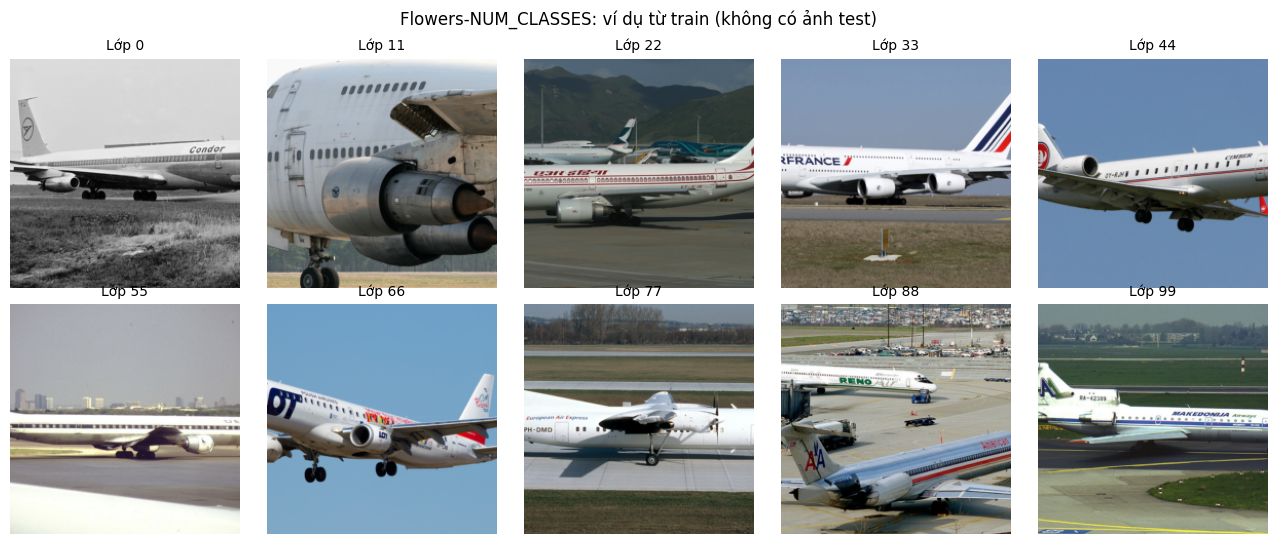

In [33]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for ax, idx in zip(axes.flat, np.linspace(0, len(flowers_train_clean) - 1, 10, dtype=int)):
    img, target = flowers_train_clean[int(idx)]
    arr = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(np.clip(arr, 0.0, 1.0))
    ax.set_title(f"Lớp {target}", fontsize=10)
    ax.axis("off")
fig.suptitle("Flowers-NUM_CLASSES: ví dụ từ train (không có ảnh test)")
plt.tight_layout(); plt.show()


## 3. Khám phá pretrained ResNet18: backbone, head và số tham số

**ResNet18** là CNN sâu có các residual connections giúp tối ưu hóa mạng sâu. Biểu diễn trước classifier có **512 chiều**.

- `weights=None`: khởi tạo hoàn toàn ngẫu nhiên (**scratch**).
- `weights=ResNet18_Weights.IMAGENET1K_V1`: nạp checkpoint học từ ImageNet (**pretrained**).
- Lệnh `model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)` **thay classifier 1.000 lớp bằng classifier mới NUM_CLASSES lớp**.

**Sai lầm thường gặp:** chỉ thay `model.fc` nhưng quên tối ưu hóa đúng nhóm tham số; đặt `requires_grad=False` không đồng nghĩa `model.eval()`; đặc biệt BatchNorm vẫn có running statistics nếu không xử lý.

In [34]:
def count_parameters(model: nn.Module) -> dict[str, int]:
    """Đếm tổng số tham số và số tham số được phép học."""
    total = sum(param.numel() for param in model.parameters())
    trainable = sum(param.numel() for param in model.parameters() if param.requires_grad)
    return {"Total": total, "Trainable": trainable, "Frozen": total - trainable}


def build_resnet18(num_classes: int = NUM_CLASSES, pretrained: bool = True) -> nn.Module:
    """Khởi tạo ResNet18 và thay head theo số lớp đích."""
    model = models.resnet18(weights=WEIGHTS if pretrained else None)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model


def configure_trainable(model: nn.Module, strategy: str) -> nn.Module:
    """Chọn lớp trainable: scratch, probe, partial, full."""
    if strategy not in ("scratch", "probe", "partial", "full"):
        raise ValueError(f"Chiến lược không được hỗ trợ: {strategy}")
    for parameter in model.parameters():
        parameter.requires_grad = strategy in ("scratch", "full")
    if strategy in ("probe", "partial"):
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
    if strategy == "partial":
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True
    return model


def set_training_mode(model: nn.Module, strategy: str) -> None:
    """Phân biệt `train()` với `requires_grad`; giữ Frozen BN ở eval."""
    model.train()
    if strategy in ("probe", "partial"):
        # Frozen BN: không cập nhật running_mean / running_var.
        # Với partial, các BN thuộc layer4 cũng giữ running stats ổn định khi ít dữ liệu.
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()


def build_optimizer(model: nn.Module, strategy: str) -> torch.optim.Optimizer:
    """Head học nhanh hơn backbone; tham số đóng băng không đưa vào optimizer."""
    if strategy == "scratch":
        return torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                 lr=1e-3, weight_decay=1e-4)
    if strategy == "probe":
        return torch.optim.AdamW(model.fc.parameters(), lr=3e-3, weight_decay=1e-3)
    if strategy == "partial":
        return torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    if strategy == "full":
        return torch.optim.AdamW([
            {"params": list(model.conv1.parameters()) + list(model.bn1.parameters()) +
                       list(model.layer1.parameters()) + list(model.layer2.parameters()), "lr": 1e-5},
            {"params": model.layer3.parameters(), "lr": 3e-5},
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-4)
    raise ValueError(strategy)


shape_demo = build_resnet18(num_classes=NUM_CLASSES, pretrained=False)
probe_demo = configure_trainable(copy.deepcopy(shape_demo), "probe")
partial_demo = configure_trainable(copy.deepcopy(shape_demo), "partial")
full_demo = configure_trainable(copy.deepcopy(shape_demo), "full")
display(pd.DataFrame([
    {"Chiến lược": "Scratch", **count_parameters(shape_demo)},
    {"Chiến lược": "Frozen + head", **count_parameters(probe_demo)},
    {"Chiến lược": "Layer4 + head", **count_parameters(partial_demo)},
    {"Chiến lược": "All layers", **count_parameters(full_demo)},
]))
assert probe_demo.fc.out_features == NUM_CLASSES
assert 0 < count_parameters(probe_demo)["Trainable"] < count_parameters(partial_demo)["Trainable"]
assert count_parameters(partial_demo)["Trainable"] < count_parameters(full_demo)["Trainable"]
del shape_demo, probe_demo, partial_demo, full_demo


,Chiến lược,Total,Trainable,Frozen
0,Scratch,11227812,11227812,0
1,Frozen + head,11227812,51300,11176512
2,Layer4 + head,11227812,8445028,2782784
3,All layers,11227812,11227812,0


## 4. Thiết kế hàm train/evaluate tái sử dụng

Quy trình: `zero_grad → forward → CrossEntropyLoss(logits, labels) → backward → optimizer.step`.

- `model.train()` cho train; `model.eval()` + `torch.inference_mode()` cho evaluate.
- **`CrossEntropyLoss` nhận logits**, không gọi `softmax` trước loss.
- Tổng hợp loss theo **số mẫu** (`loss.item() * batch_size`), không trung bình các trung bình batch khi batch cuối nhỏ.
- Chỉ dùng **validation loss** để chọn checkpoint / early stopping, báo cáo macro-F1 và top-5 như metrics bổ sung.
- Với tập ít mẫu, biến động giữa seed có thể lớn;

In [35]:
def evaluate(model: nn.Module, loader: DataLoader, num_classes: int = NUM_CLASSES) -> dict:
    """Đánh giá đầy đủ theo mẫu, trả về nhãn để tính macro-F1 và top-k."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, total, correct_1, correct_5 = 0.0, 0, 0, 0
    all_targets, all_preds = [], []
    with torch.inference_mode():
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(inputs)
            total_loss += criterion(logits, targets).item()
            preds = logits.argmax(dim=1)
            correct_1 += int((preds == targets).sum())
            correct_5 += int((logits.topk(min(5, num_classes), dim=1).indices ==
                               targets.unsqueeze(1)).any(dim=1).sum())
            total += targets.size(0)
            all_targets.extend(targets.cpu().tolist())
            all_preds.extend(preds.cpu().tolist())
    assert total > 0
    return {"loss": total_loss / total, "accuracy": correct_1 / total,
            "top5": correct_5 / total,
            "macro_f1": f1_score(all_targets, all_preds, labels=list(range(num_classes)),
                                 average="macro", zero_division=0),
            "targets": np.asarray(all_targets), "preds": np.asarray(all_preds)}


def fit_model(name: str, model: nn.Module, train_data: DataLoader,
              val_data: DataLoader, strategy: str, epochs: int,
              num_classes: int = NUM_CLASSES) -> tuple[nn.Module, pd.DataFrame, dict]:
    """Huấn luyện, in từng epoch, lưu best checkpoint theo validation loss."""
    model = model.to(DEVICE)
    optimizer = build_optimizer(model, strategy)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    criterion = nn.CrossEntropyLoss()
    history, best_state = [], None
    best_loss, best_epoch, patience_count = float("inf"), 0, 0
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        set_training_mode(model, strategy)
        total_loss, num_seen = 0.0, 0
        for inputs, targets in train_data:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(targets)
            num_seen += len(targets)
        val_metrics = evaluate(model, val_data, num_classes)
        epoch_record = {"epoch": epoch, "train_loss": total_loss / num_seen,
                        "val_loss": val_metrics["loss"], "val_acc": val_metrics["accuracy"],
                        "val_f1": val_metrics["macro_f1"], "val_top5": val_metrics["top5"]}
        history.append(epoch_record)
        print(f"[{name}] {epoch:02d}/{epochs:02d} | train_loss={epoch_record['train_loss']:.4f} "
              f"| val_loss={epoch_record['val_loss']:.4f} | val_acc={epoch_record['val_acc']:.2%} "
              f"| val_macroF1={epoch_record['val_f1']:.4f}")
        # Quy tắc nhất quán: mọi phương pháp chọn checkpoint bằng val_loss.
        if val_metrics["loss"] < best_loss - 1e-6:
            best_loss, best_epoch, patience_count = val_metrics["loss"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_count += 1
        scheduler.step()
        if patience_count >= PATIENCE:
            print(f"[{name}] Early stopping tại epoch {epoch}.")
            break
    if best_state is None:
        raise RuntimeError("Không có checkpoint hợp lệ")
    model.load_state_dict(best_state)
    metrics = evaluate(model, val_data, num_classes)
    seconds = time.perf_counter() - start
    summary = {"Mô hình": name, "Best epoch": best_epoch,
               "Val loss": metrics["loss"], "Val accuracy": metrics["accuracy"],
               "Val macro-F1": metrics["macro_f1"], "Val top-5": metrics["top5"],
               "Thời gian (s)": round(seconds, 1),
               "Trainable": count_parameters(model)["Trainable"]}
    print(f"[{name}] BEST epoch={best_epoch}, val_loss={metrics['loss']:.4f}, "
          f"val_accuracy={metrics['accuracy']:.2%}")
    return model, pd.DataFrame(history), summary


def plot_histories(histories: dict[str, pd.DataFrame], title: str) -> None:
    """Trực quan hóa lịch sử trên train/validation của các phương pháp."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for name, frame in histories.items():
        axes[0].plot(frame.epoch, frame.val_acc, marker="o", label=name)
        axes[1].plot(frame.epoch, frame.train_loss, linestyle="--", alpha=0.5,
                     label=f"{name} train")
        axes[1].plot(frame.epoch, frame.val_loss, marker="o", label=f"{name} val")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy", ylim=(0, 1))
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy", title="Train loss / Val loss")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


## 5. Thí nghiệm A — ResNet18 **huấn luyện từ đầu** (baseline)

Khởi tạo `weights=None` rồi tối ưu hóa toàn bộ mạng. **Không coi 5 epoch là đủ cho scratch hội tụ**.

**Giả thuyết:** với 10 ảnh/lớp, scratch khó hình thành representation có khả năng tổng quát trong ngân sách nhỏ.

In [36]:
histories, fitted_models, summaries = {}, {}, {}
set_seed(SEED)
scratch_model = configure_trainable(build_resnet18(pretrained=False), "scratch")
scratch_model, histories["Scratch"], summaries["Scratch"] = fit_model(
    "Scratch", scratch_model, train_loader, val_loader,
    strategy="scratch", epochs=EPOCHS_SCRATCH)
fitted_models["Scratch"] = scratch_model.cpu()
display(pd.DataFrame([summaries["Scratch"]]).round(4))
del scratch_model
torch.cuda.empty_cache()


[Scratch] 01/05 | train_loss=4.7127 | val_loss=4.5564 | val_acc=1.95% | val_macroF1=0.0062
[Scratch] 02/05 | train_loss=4.5526 | val_loss=4.4911 | val_acc=2.82% | val_macroF1=0.0070
[Scratch] 03/05 | train_loss=4.4443 | val_loss=4.4611 | val_acc=3.33% | val_macroF1=0.0168
[Scratch] 04/05 | train_loss=4.3146 | val_loss=4.3231 | val_acc=4.02% | val_macroF1=0.0229
[Scratch] 05/05 | train_loss=4.2010 | val_loss=4.1215 | val_acc=6.48% | val_macroF1=0.0398
[Scratch] BEST epoch=5, val_loss=4.1215, val_accuracy=6.48%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Scratch,5,4.1215,0.0648,0.0398,0.2181,449.4,11227812


## 6. Thí nghiệm B — **Frozen feature extractor + linear probing**

**Ý tưởng:** giữ nguyên toàn bộ trọng số ImageNet của backbone, trích xuất vector 512 chiều và chỉ học một **linear classifier** NUM_CLASSES đầu ra. Đây là cách transfer learning nhanh, đặc biệt phù hợp dữ liệu ít.

**Tối ưu hóa đặc biệt:** với backbone đóng băng và biến đổi input **deterministic**, có thể cache embeddings một lần. Sau đó train head trên tensor 512 chiều.

**Lưu ý công bằng:** head dùng deterministic crop trong khi scratch/partial/full dùng augmentation; có thể xem đây là khác biệt pipeline có chủ đích, không phải một *ablation* chỉ thay đúng một biến. Để kiểm chứng thuần túy tác động pretrained, giữ transform và số lần cập nhật tương đương.

In [37]:
from torch.utils.data import DataLoader

bs = BATCH_SIZE if 'BATCH_SIZE' in globals() else 32
nw = NUM_WORKERS if 'NUM_WORKERS' in globals() else 2

train_loader = DataLoader(
    flowers_train, batch_size=bs, shuffle=True, num_workers=nw, pin_memory=True
)
train_clean_loader = DataLoader(
    flowers_train_clean,
    batch_size=bs,
    shuffle=False,
    num_workers=nw,
    pin_memory=True,
)
val_loader = DataLoader(
    flowers_val, batch_size=bs, shuffle=False, num_workers=nw, pin_memory=True
)
test_loader = DataLoader(
    flowers_test, batch_size=bs, shuffle=False, num_workers=nw, pin_memory=True
)

print(
    f'Đã tạo xong DataLoader: {len(train_loader)} train batches |'
    f' {len(val_loader)} val batches | {len(test_loader)} test batches'
)

Đã tạo xong DataLoader: 105 train batches | 105 val batches | 105 test batches


In [38]:
def extract_features(pretrained_model: nn.Module, loader: DataLoader) -> TensorDataset:
    """Trích xuất một vector đặc trưng cho mỗi ảnh; không tính gradient."""
    backbone = copy.deepcopy(pretrained_model)
    backbone.fc = nn.Identity()
    backbone = backbone.to(DEVICE).eval()
    vectors, labels = [], []
    with torch.inference_mode():
        for images, targets in loader:
            features = backbone(images.to(DEVICE, non_blocking=True))
            vectors.append(features.cpu())
            labels.append(targets.clone())
    del backbone
    return TensorDataset(torch.cat(vectors), torch.cat(labels))


class LinearProbe(nn.Module):
    """Head tuyến tính dùng cho embeddings 512 chiều đã được cache."""
    def __init__(self, in_features: int = 512, out_features: int = NUM_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(x)


pretrained_probe = build_resnet18(pretrained=True)
# Có thể kiểm tra tài nguyên: NUM_CLASSES0 x 512 số float32 ≈ 2 MB mỗi split.
cached_train = extract_features(pretrained_probe, train_clean_loader)
cached_val = extract_features(pretrained_probe, val_loader)
print("Cached train:", tuple(cached_train.tensors[0].shape),
      "| Cached val:", tuple(cached_val.tensors[0].shape))
probe_train_loader = DataLoader(cached_train, batch_size=128, shuffle=True)
probe_val_loader = DataLoader(cached_val, batch_size=256, shuffle=False)
set_seed(SEED)
probe_head = LinearProbe()
probe_head, histories["Linear probe"], summaries["Linear probe"] = fit_model(
    "Linear probe", probe_head, probe_train_loader, probe_val_loader,
    strategy="probe", epochs=EPOCHS_PROBE)
# Khi cần inference trên ảnh, ghép head đã học vào backbone pretrained.
pretrained_probe.fc.load_state_dict(probe_head.fc.cpu().state_dict())
fitted_models["Linear probe"] = configure_trainable(pretrained_probe.cpu(), "probe")
summaries["Linear probe"]["Trainable"] = count_parameters(fitted_models["Linear probe"])["Trainable"]
display(pd.DataFrame([summaries["Linear probe"]]).round(4))
del probe_head, cached_train, cached_val, pretrained_probe
torch.cuda.empty_cache()


Cached train: (3334, 512) | Cached val: (3333, 512)
[Linear probe] 01/25 | train_loss=4.5876 | val_loss=4.0416 | val_acc=9.78% | val_macroF1=0.0803
[Linear probe] 02/25 | train_loss=3.5194 | val_loss=3.5334 | val_acc=19.65% | val_macroF1=0.1658
[Linear probe] 03/25 | train_loss=2.9638 | val_loss=3.3510 | val_acc=22.35% | val_macroF1=0.1988
[Linear probe] 04/25 | train_loss=2.6171 | val_loss=3.2268 | val_acc=23.19% | val_macroF1=0.2084
[Linear probe] 05/25 | train_loss=2.3702 | val_loss=3.0649 | val_acc=26.94% | val_macroF1=0.2472
[Linear probe] 06/25 | train_loss=2.1560 | val_loss=2.9366 | val_acc=29.22% | val_macroF1=0.2727
[Linear probe] 07/25 | train_loss=1.9890 | val_loss=2.9404 | val_acc=29.67% | val_macroF1=0.2831
[Linear probe] 08/25 | train_loss=1.8347 | val_loss=2.8514 | val_acc=30.78% | val_macroF1=0.2918
[Linear probe] 09/25 | train_loss=1.7424 | val_loss=2.8190 | val_acc=31.02% | val_macroF1=0.2991
[Linear probe] 10/25 | train_loss=1.6325 | val_loss=2.7746 | val_acc=32.13% 

,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Linear probe,25,2.6007,0.3657,0.3622,0.6484,2.2,51300


## 7. Thí nghiệm C — **Partial fine-tuning** (`layer4` + head)

Đóng băng `conv1`, `bn1`, `layer1..3`, mở **`layer4`** và head. So với linear probing, tầng cao được điều chỉnh để phân biệt các loại hoa gần giống nhau.

**BatchNorm:** chỉ `requires_grad=False` không khóa `running_mean/var`; ở dữ liệu ít, ta cố ý đặt **mọi BatchNorm ở `eval()`** trong lúc train partial. Các trọng số affine của BN thuộc `layer4` vẫn có thể cập nhật nếu `requires_grad=True`. Đây là một lựa chọn thiết kế, cần ghi rõ.

**Discriminative learning rates:** `layer4` dùng `1e-4`, head dùng `1e-3`; backbone pretrained thay đổi chậm hơn head mới.

In [39]:
set_seed(SEED)
partial_model = configure_trainable(build_resnet18(pretrained=True), "partial")
print("Số tham số partial:", count_parameters(partial_model))
partial_model, histories["Partial FT"], summaries["Partial FT"] = fit_model(
    "Partial FT", partial_model, train_loader, val_loader,
    strategy="partial", epochs=EPOCHS_PARTIAL)
fitted_models["Partial FT"] = partial_model.cpu()
display(pd.DataFrame([summaries["Partial FT"]]).round(4))
del partial_model
torch.cuda.empty_cache()


Số tham số partial: {'Total': 11227812, 'Trainable': 8445028, 'Frozen': 2782784}
[Partial FT] 01/05 | train_loss=4.5227 | val_loss=4.1218 | val_acc=5.37% | val_macroF1=0.0200
[Partial FT] 02/05 | train_loss=3.6296 | val_loss=3.2866 | val_acc=16.20% | val_macroF1=0.1200
[Partial FT] 03/05 | train_loss=2.6544 | val_loss=2.9719 | val_acc=19.92% | val_macroF1=0.1772
[Partial FT] 04/05 | train_loss=1.9262 | val_loss=2.5962 | val_acc=30.15% | val_macroF1=0.2843
[Partial FT] 05/05 | train_loss=1.4493 | val_loss=2.5208 | val_acc=33.30% | val_macroF1=0.3278
[Partial FT] BEST epoch=5, val_loss=2.5208, val_accuracy=33.30%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Partial FT,5,2.5208,0.333,0.3278,0.6766,514.1,8445028


## 8. Thí nghiệm D — **Full fine-tuning** với learning rate theo tầng

Mở toàn bộ backbone và head. Dùng 4 nhóm learning rate để **tầng thấp thay đổi ít, tầng cao thay đổi nhiều**. Đây là full fine-tuning (khác **training from scratch** vì bắt đầu từ pretrained weights).

`AdamW` cho regularization, `CosineAnnealingLR` giảm learning rate. Vì bộ dữ liệu có ít mẫu, cần cân nhắc lịch mở dần tầng (*gradual unfreezing*) và early stopping. Có thể thử chiến lược **warm-start** từ head của linear probe ở bài tập mở rộng; ở đây head mới được khởi tạo ngẫu nhiên để phân biệt rõ cách huấn luyện.

In [40]:
set_seed(SEED)
full_model = configure_trainable(build_resnet18(pretrained=True), "full")
print("Learning rates (full):", [group["lr"] for group in build_optimizer(full_model, "full").param_groups])
full_model, histories["Full FT"], summaries["Full FT"] = fit_model(
    "Full FT", full_model, train_loader, val_loader,
    strategy="full", epochs=EPOCHS_FULL)
fitted_models["Full FT"] = full_model.cpu()
display(pd.DataFrame([summaries["Full FT"]]).round(4))
del full_model
torch.cuda.empty_cache()


Learning rates (full): [1e-05, 3e-05, 0.0001, 0.001]
[Full FT] 01/05 | train_loss=4.0002 | val_loss=3.1152 | val_acc=23.43% | val_macroF1=0.1914
[Full FT] 02/05 | train_loss=2.2804 | val_loss=2.4859 | val_acc=33.84% | val_macroF1=0.3101
[Full FT] 03/05 | train_loss=1.4468 | val_loss=2.2167 | val_acc=38.40% | val_macroF1=0.3699
[Full FT] 04/05 | train_loss=1.0202 | val_loss=2.0522 | val_acc=43.71% | val_macroF1=0.4192
[Full FT] 05/05 | train_loss=0.8181 | val_loss=2.0039 | val_acc=45.12% | val_macroF1=0.4443
[Full FT] BEST epoch=5, val_loss=2.0039, val_accuracy=45.12%


,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Full FT,5,2.0039,0.4512,0.4443,0.7783,519.2,11227812


## 9. Tổng hợp và so sánh kết quả **validation**

**Chọn mô hình trước khi mở test:** xếp theo `Val loss` tăng dần; khi bằng nhau, xếp theo `Val macro-F1` giảm dần. Cột thời gian của linear probe chỉ đo huấn luyện head, chưa tính thời gian cache embeddings, nên **không so sánh tổng chi phí trực tiếp**.

Một so sánh đầy đủ cần: ngân sách compute tương đương, nhiều seed, cùng chính sách augmentation và tuning riêng cho scratch.

,Mô hình,Best epoch,Val loss,Val accuracy,Val macro-F1,Val top-5,Thời gian (s),Trainable
0,Full FT,5,2.0039,0.4512,0.4443,0.7783,519.2,11227812
1,Partial FT,5,2.5208,0.3330,0.3278,0.6766,514.1,8445028
2,Linear probe,25,2.6007,0.3657,0.3622,0.6484,2.2,51300
3,Scratch,5,4.1215,0.0648,0.0398,0.2181,449.4,11227812


Mô hình được chọn CHỈ từ validation: Full FT


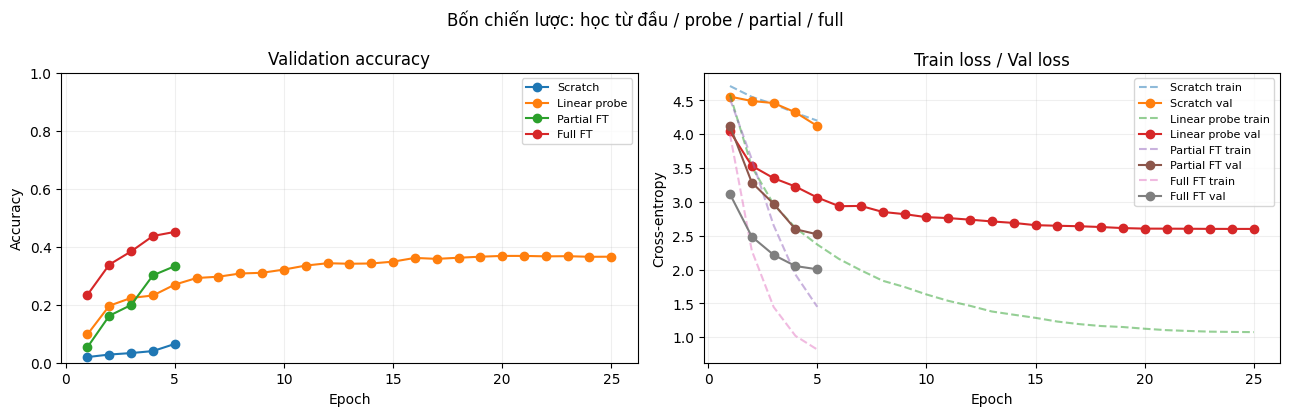

In [41]:
comparison = pd.DataFrame(summaries.values()).sort_values(
    ["Val loss", "Val macro-F1"], ascending=[True, False]).reset_index(drop=True)
display(comparison.round(4))
selected_name = str(comparison.iloc[0]["Mô hình"])
best_model = fitted_models[selected_name].to(DEVICE).eval()
print("Mô hình được chọn CHỈ từ validation:", selected_name)
plot_histories(histories, "Bốn chiến lược: học từ đầu / probe / partial / full")
comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)


## 10. **Đánh giá test đúng một lần** và phân tích sai số

Test chính thức có 6.149 ảnh, dùng để **ước lượng hiệu quả ngoài mẫu sau khi chọn mô hình bằng validation**. Không dùng kết quả test để quay lại chọn hyperparameter. Macro-F1 trên test không nhất thiết trùng accuracy vì số lượng ảnh/lớp khác nhau.

In [48]:
DATA_ROOT = '/content/data'

flowers_test = datasets.FGVCAircraft(
    DATA_ROOT,
    split='test',
    annotation_level='variant',
    download=False,
    transform=eval_transform,
)
assert len(flowers_test) == 3333
test_loader = DataLoader(
    flowers_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)
print(f'Đã nạp xong tập Test máy bay: {len(flowers_test)} ảnh')

Đã nạp xong tập Test máy bay: 3333 ảnh


In [51]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
import torch
import torch.nn as nn

# Khai báo lại device và đưa best_model lên GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_eval = best_model.to(device)
model_eval.eval()

all_preds, all_targets, total_loss, total_samples = [], [], 0.0, 0
criterion = nn.CrossEntropyLoss()

with torch.no_grad():
  for x, y in test_loader:
    x, y = x.to(device), y.to(device)
    logits = model_eval(x)
    loss = criterion(logits, y)
    total_loss += loss.item() * y.size(0)
    total_samples += y.size(0)
    all_preds.append(logits.argmax(dim=1).cpu().numpy())
    all_targets.append(y.cpu().numpy())

preds = np.concatenate(all_preds)
targets = np.concatenate(all_targets)

test_metrics = {
    "loss": total_loss / total_samples,
    "acc": accuracy_score(targets, preds),
    "macro_f1": f1_score(targets, preds, average="macro"),
    "preds": preds,
    "targets": targets,
}
print(
    f"Test Loss: {test_metrics['loss']:.4f} | Test Accuracy:"
    f" {test_metrics['acc']:.4f} | Macro-F1: {test_metrics['macro_f1']:.4f}"
)

Test Loss: 2.0081 | Test Accuracy: 0.4566 | Macro-F1: 0.4486


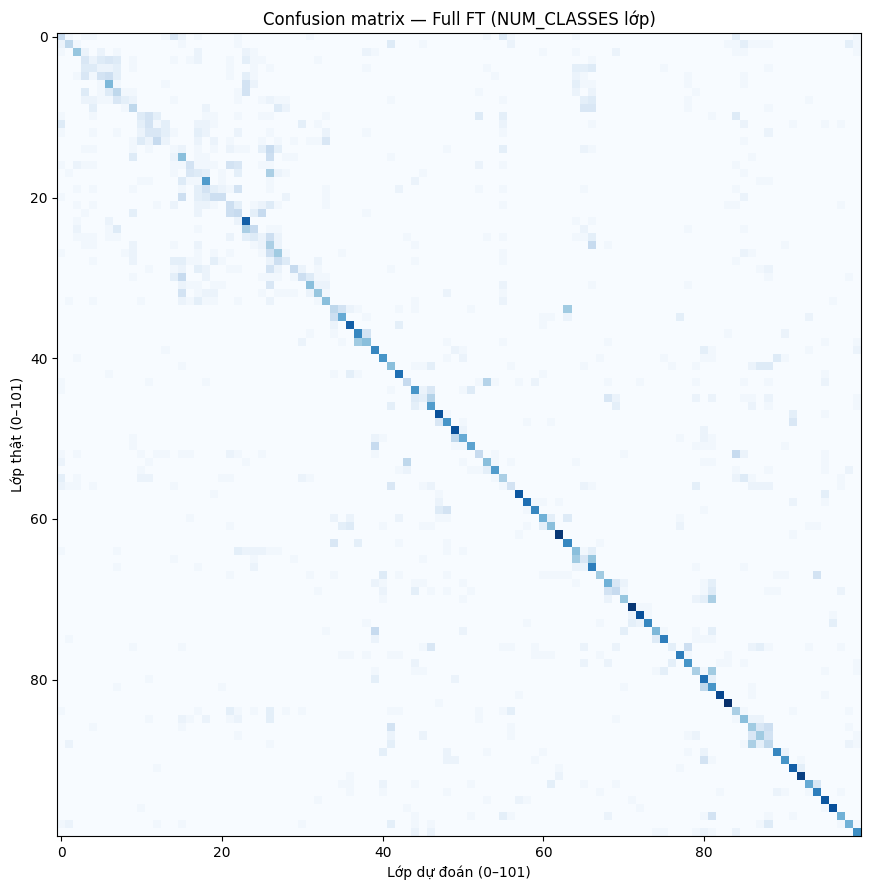

10 lớp có F1 thấp nhất:


,precision,recall,f1-score,support
Flower 014,0.040,0.029,0.034,34.0
Flower 025,0.071,0.061,0.066,33.0
Flower 013,0.167,0.061,0.089,33.0
Flower 017,0.089,0.118,0.101,34.0
Flower 019,0.115,0.091,0.102,33.0
Flower 045,0.176,0.091,0.120,33.0
Flower 004,0.160,0.121,0.138,33.0
Flower 065,0.143,0.147,0.145,34.0
Flower 076,0.429,0.091,0.150,33.0
Flower 008,0.500,0.088,0.150,34.0


In [52]:
label_names = [f"Flower {i:03d}" for i in range(NUM_CLASSES)]
cm = confusion_matrix(test_metrics["targets"], test_metrics["preds"],
                      labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.set(xlabel="Lớp dự đoán (0–101)", ylabel="Lớp thật (0–101)",
       title=f"Confusion matrix — {selected_name} (NUM_CLASSES lớp)")
plt.tight_layout(); plt.show()
class_report = classification_report(
    test_metrics["targets"], test_metrics["preds"],
    labels=np.arange(NUM_CLASSES), target_names=label_names,
    zero_division=0, output_dict=True)
class_table = pd.DataFrame(class_report).T.iloc[:NUM_CLASSES]
print("10 lớp có F1 thấp nhất:")
display(class_table.sort_values("f1-score").head(10).round(3))
class_table.to_csv(OUTPUT_DIR / "test_per_class_metrics.csv")


Tổng ảnh dự đoán sai: 1811 / 3333


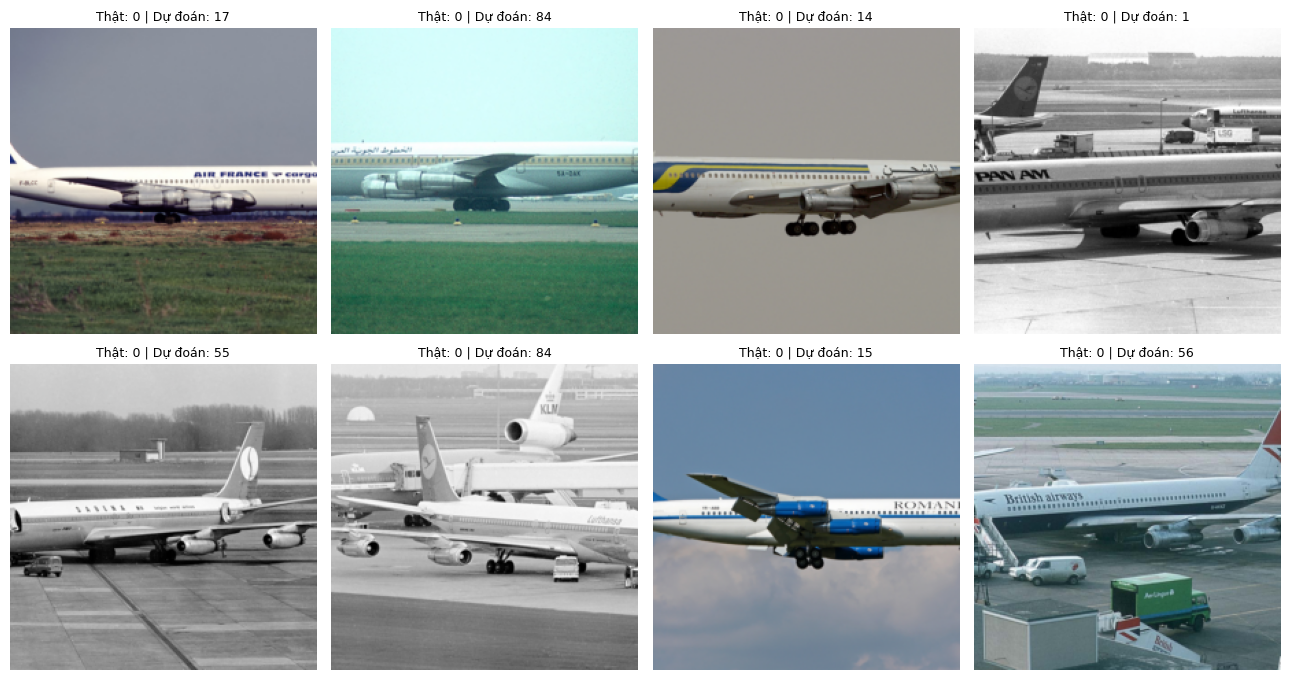

In [53]:
mistakes = np.where(test_metrics["targets"] != test_metrics["preds"])[0]
print("Tổng ảnh dự đoán sai:", len(mistakes), "/", len(flowers_test))
if len(mistakes) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, idx in zip(axes.flat, mistakes[:8]):
        tensor, true_label = flowers_test[int(idx)]
        arr = tensor.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
        ax.imshow(np.clip(arr, 0, 1))
        ax.set_title(f"Thật: {true_label} | Dự đoán: {test_metrics['preds'][idx]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()


## 11. Lưu/tải checkpoint và suy luận một ảnh

Chỉ lưu **mô hình tốt nhất chọn bằng validation**; đóng gói trọng số, tên kiến trúc, số lớp, preprocessing và thông tin lựa chọn để có thể tái tạo inference. Tải bằng `weights_only=True` (chỉ tải từ nguồn tin cậy).

In [55]:
checkpoint_path = OUTPUT_DIR / "flowersNUM_CLASSES_best_resnet18.pt"
# Lưu dict chỉ gồm tensor và dữ liệu cơ bản, tương thích `weights_only=True`.
torch.save({
    "architecture": "resnet18", "num_classes": NUM_CLASSES,
    "selected_strategy": selected_name, "state_dict": {
        key: value.detach().cpu() for key, value in best_model.state_dict().items()
    },
    "image_size": IMAGE_SIZE, "normalization_mean": MEAN,
    "normalization_std": STD, "val_loss": float(comparison.iloc[0]["Val loss"]),
}, checkpoint_path)
payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored_model = build_resnet18(num_classes=payload["num_classes"], pretrained=False)
restored_model.load_state_dict(payload["state_dict"])
restored_model = restored_model.to(DEVICE).eval()
example_tensor, example_target = flowers_test[0]
with torch.inference_mode():
    before = best_model(example_tensor.unsqueeze(0).to(DEVICE)).cpu()
    after = restored_model(example_tensor.unsqueeze(0).to(DEVICE)).cpu()
assert torch.allclose(before, after, atol=1e-5, rtol=1e-5)
probabilities = after.softmax(dim=1)[0]
values, indices = probabilities.topk(5)
display(pd.DataFrame({"Lớp dự đoán": indices.tolist(),
                      "Xác suất": values.tolist()}))
print(
    "Checkpoint:",
    checkpoint_path,
    "| Kích thước (MB):",
    round(checkpoint_path.stat().st_size / (1024**2), 1),
)
print("Reload khớp logits:", bool(torch.allclose(before, after, atol=1e-5, rtol=1e-5)))


,Lớp dự đoán,Xác suất
0,17,0.195315
1,0,0.132122
2,30,0.088096
3,55,0.081278
4,11,0.041009


Checkpoint: bai6_aircraft_outputs/flowersNUM_CLASSES_best_resnet18.pt | Kích thước (MB): 42.9
Reload khớp logits: True
